In [ ]:
import sys
parent_dir = "C:/Users/Drew/Documents/MyFiles/work/networks/dep_src"
if str(parent_dir) not in sys.path:
    sys.path.append(str(parent_dir))

from graph_utils import create_layered_graph, assign_properties # pyright: ignore[reportMissingImports]
from lp import standard_max_flow, build_max_flow_model # pyright: ignore[reportMissingImports]

layer_sizes = [2, 5, 2, 5, 3, 2]
G, layers = create_layered_graph(layer_sizes)
G = assign_properties(G, layer_sizes)
result, flow_dict = standard_max_flow(G)
result

{'Problem': [{'Lower bound': 21.0, 'Upper bound': 21.0, 'Number of objectives': 1, 'Number of constraints': 68, 'Number of variables': 52, 'Sense': 'maximize'}], 'Solver': [{'Status': 'ok', 'Termination condition': 'optimal', 'Termination message': 'TerminationCondition.optimal'}]}

In [ ]:
from tqdm import trange
import numpy as np 
import pandas as pd
import networkx as nx
import pyomo.environ as pyo

def sample_states(rng, node_p, edge_p):
    node_state = rng.binomial(1, node_p)
    edge_state = rng.binomial(1, edge_p)
    return node_state, edge_state

def preprocess_network_simulation(G):
    nodes = list(G.nodes())
    edges = list(G.edges())
    node_p = np.array([G.nodes[n].get('probability1', 1) for n in nodes])
    edge_p = np.array([G.edges[u,v].get('probability', 1) for u,v in edges])
    return nodes, edges, node_p,  edge_p

def stochastic_max_flow(G, n_sim=1000, seed=123, solver_str='appsi_highs'):

    model = build_max_flow_model(G)
    rng = np.random.default_rng(seed)
    solver = pyo.SolverFactory(solver_str)
    nodes, edges, node_p, edge_p = preprocess_network_simulation(G)

    results = []

    for i in trange(n_sim):
        node_state, edge_state = sample_states(rng, node_p, edge_p)
        for n in model.nodes:
            model.node_state[n] = node_state[n]
        for (u, v), state in zip(edges, edge_state):
            model.edge_state[u, v] = int(state)


        result = solver.solve(model)
        flow = pyo.value(model.F)    
        node_operational = int(node_state.sum())
        node_failed = len(nodes) - node_operational
        edge_operational = int(edge_state.sum())
        edge_failed = len(edges) - edge_operational

        row = {
            'sim_number': i, 'flow': flow, 
            'node_operational': node_operational, 'node_failed': node_failed, 
            'edge_operational': edge_operational, 'edge_failed': edge_failed,
            'node_opr_ratio': node_operational/len(nodes), 'edge_opr_ratio': edge_operational/len(edges),
            'termination_condition': str(result.solver.termination_condition),
            'flow_failure_indicator': 1 if flow == 0 else 0
        }
        # Node states
        for n, state in zip(nodes, node_state):
            row[f'node_{n}'] = int(state)
        # Edge states
        for (u, v), state in zip(edges, edge_state):
            row[f'edge_({u},{v})'] = int(state)
        results.append(row)
    return pd.DataFrame(results)

df = stochastic_max_flow(G)

100%|██████████| 1000/1000 [00:04<00:00, 248.76it/s]


In [56]:
df.head()


,sim_number,flow,node_operational,node_failed,edge_operational,edge_failed,node_opr_ratio,edge_opr_ratio,termination_condition,flow_failure_indicator,...,"edge_(12,16)","edge_(13,14)","edge_(13,15)","edge_(13,16)","edge_(14,17)","edge_(14,18)","edge_(15,17)","edge_(15,18)","edge_(16,17)","edge_(16,18)"
0,0,7.0,18,1,47,4,0.947368,0.921569,optimal,0,...,1,1,1,1,1,1,1,1,1,1
1,1,7.0,18,1,49,2,0.947368,0.960784,optimal,0,...,1,1,1,1,1,1,1,1,1,1
2,2,5.0,17,2,47,4,0.894737,0.921569,optimal,0,...,1,1,1,1,1,1,1,1,0,1
3,3,15.0,19,0,45,6,1.000000,0.882353,optimal,0,...,1,1,1,1,1,1,1,1,1,1
4,4,8.0,17,2,49,2,0.894737,0.960784,optimal,0,...,1,1,1,1,1,1,1,1,1,1


In [54]:
import re 
def component_flow_impact(df, component_columns):
    results = []
    for component in component_columns:
        flow_operational = df.loc[df[component] == 1, 'flow'].mean()
        flow_failed = df.loc[df[component] == 0, 'flow'].mean()
        results.append({
            'component': component,
            'flow_if_operational': flow_operational,
            'flow_if_failed': flow_failed,
            'flow_difference': flow_operational - flow_failed,
            'n_operational': (df[component] == 1).sum(),
            'n_failed': (df[component] == 0).sum(),
            'observed_performance_rate': (df[component] == 1).sum()/df.shape[0]
        })
    return pd.DataFrame(results).sort_values('flow_difference',ascending=False).reset_index(drop=True)

node_cols = [c for c in df.columns if re.match(r"\bnode_(\d+)\b", c)]
edge_cols = [c for c in df.columns if re.match(r'^edge_\(\d+,\d+\)$',c)]
node_impact = component_flow_impact(df,node_cols)
edge_impact = component_flow_impact(df,edge_cols)

edge_impact

,component,flow_if_operational,flow_if_failed,flow_difference,n_operational,n_failed,observed_performance_rate
0,"edge_(14,18)",9.033266,5.750000,3.283266,992,8,0.992
1,"edge_(16,17)",9.021106,6.200000,2.821106,995,5,0.995
2,"edge_(10,15)",9.039474,6.333333,2.706140,988,12,0.988
3,"edge_(8,10)",9.028283,6.900000,2.128283,990,10,0.990
4,"edge_(5,8)",9.028455,7.687500,1.340955,984,16,0.984
5,"edge_(4,7)",9.190198,7.909091,1.281107,857,143,0.857
6,"edge_(15,17)",9.012048,7.750000,1.262048,996,4,0.996
7,"edge_(7,12)",9.019192,7.800000,1.219192,990,10,0.990
8,"edge_(10,14)",9.017154,7.888889,1.128266,991,9,0.991
9,"edge_(4,8)",9.133646,8.272109,0.861537,853,147,0.853


In [46]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.inspection import permutation_importance

X = df[node_cols + edge_cols]
y = df['flow']

X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2,random_state=123)
model = RandomForestRegressor(n_estimators=300,random_state=123,n_jobs=-1)
model.fit(X_train, y_train)
pred = model.predict(X_test)

print("R-squared:", r2_score(y_test, pred))
print("MAE:", mean_absolute_error(y_test, pred))

importance_df = pd.DataFrame({'component': X.columns,'importance': model.feature_importances_}).sort_values('importance',ascending=False)
print(importance_df.head())

perm = permutation_importance(model,X_test,y_test,n_repeats=10,random_state=123,n_jobs=-1) # using a permutation model instead --> stratifes successes and failures
perm_imp_df = pd.DataFrame({'component': X.columns,'importance': perm.importances_mean}).sort_values('importance',ascending=False)
perm_imp_df.head()

R-squared: 0.9001458452206087
MAE: 0.7493333333333334
     component  importance
18     node_18    0.349334
17     node_17    0.284136
1       node_1    0.120559
0       node_0    0.106300
23  edge_(0,6)    0.026719


,component,importance
18,node_18,0.817799
17,node_17,0.550798
1,node_1,0.283433
0,node_0,0.174929
23,"edge_(0,6)",0.059016


In [63]:
from sklearn.ensemble import RandomForestClassifier

X = df[node_cols + edge_cols]
y = df['flow_failure_indicator']
clf = RandomForestClassifier(n_estimators=300,random_state=123,n_jobs=-1)
clf.fit(X, y)
#prob_failure = clf.predict_proba(X_test)[:, 1]


,n_estimators,300
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [64]:
from sklearn.cluster import KMeans

X = df[node_cols + edge_cols]
cluster = KMeans(n_clusters=4,random_state=123)
df['cluster'] = cluster.fit_predict(X)
df.groupby('cluster')['flow'].agg(['mean', 'std', 'min', 'max'])

c:\Users\Drew\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


,mean,std,min,max
cluster,,,,
0,8.896552,4.748897,-0.0,15.0
1,8.640777,4.604884,-0.0,15.0
2,10.037815,4.309082,-0.0,15.0
3,8.524887,4.771655,-0.0,15.0


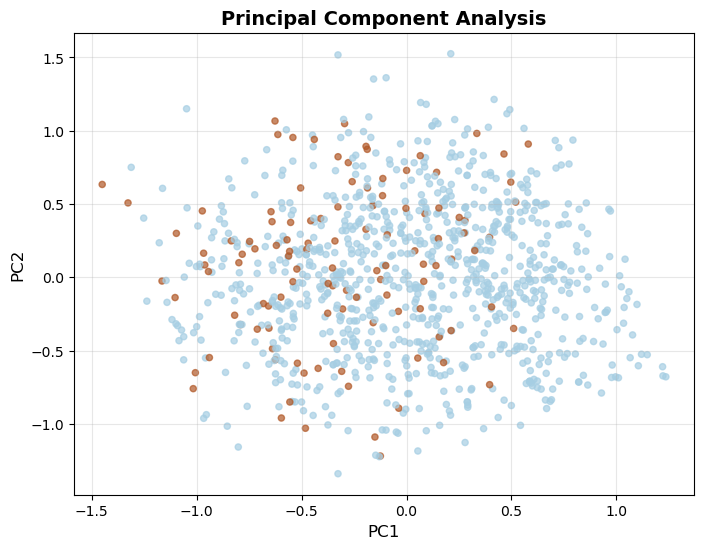

In [96]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X)

df['PC1'] = X_pca[:, 0]
df['PC2'] = X_pca[:, 1]


import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(df['PC1'], df['PC2'], alpha=0.7, s=20, c=df['flow_failure_indicator'], cmap='Paired')

plt.xlabel('PC1', fontsize=12)
plt.ylabel('PC2', fontsize=12)
plt.title('Principal Component Analysis', fontsize=14, weight='bold')
plt.grid(True, alpha=0.3)

plt.show()

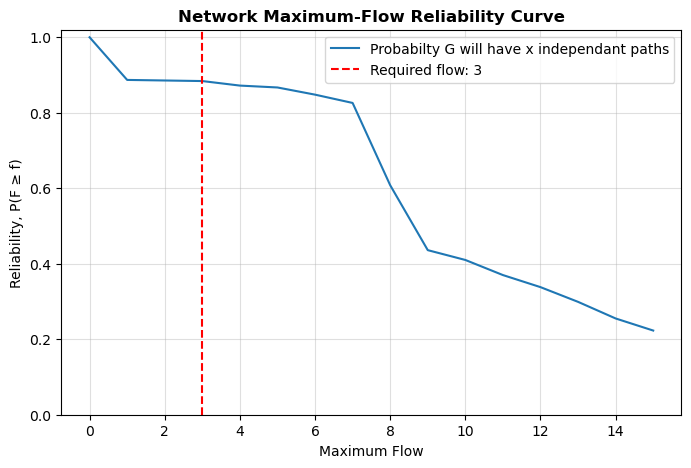

In [ ]:
flow_values = np.sort(df['flow'])
reliability = np.array([np.mean(df['flow'] >= f)for f in flow_values])
flow_requirement = 3

plt.figure(figsize=(8, 5))

plt.plot(flow_values, reliability, label=f'Probabilty G will have x independent paths')
plt.axvline(flow_requirement,linestyle='--',label=f'Required flow: {flow_requirement}', c='red')


plt.xlabel('Maximum Flow')
plt.ylabel('Reliability, P(F ≥ f)')
plt.title('Network Maximum-Flow Reliability Curve', weight='bold')
plt.ylim(0, 1.02)
plt.legend(bbox_to_anchor=(1,1))
plt.grid(True, alpha=0.4)
plt.show()


 97%|=================== | 968/1000 [00:21<00:00]       

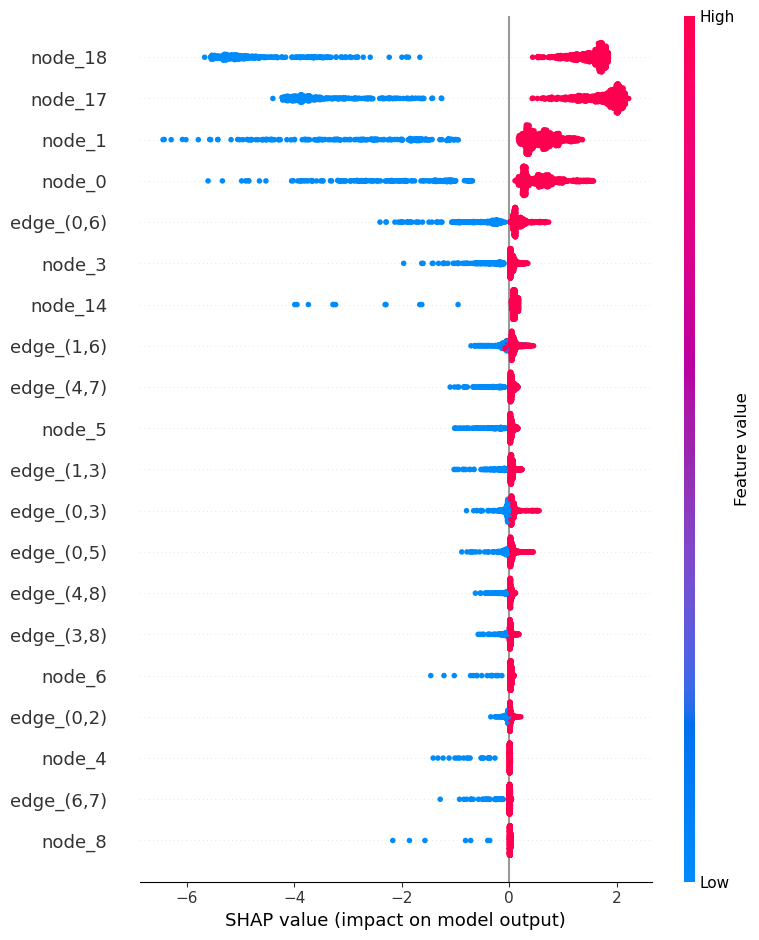

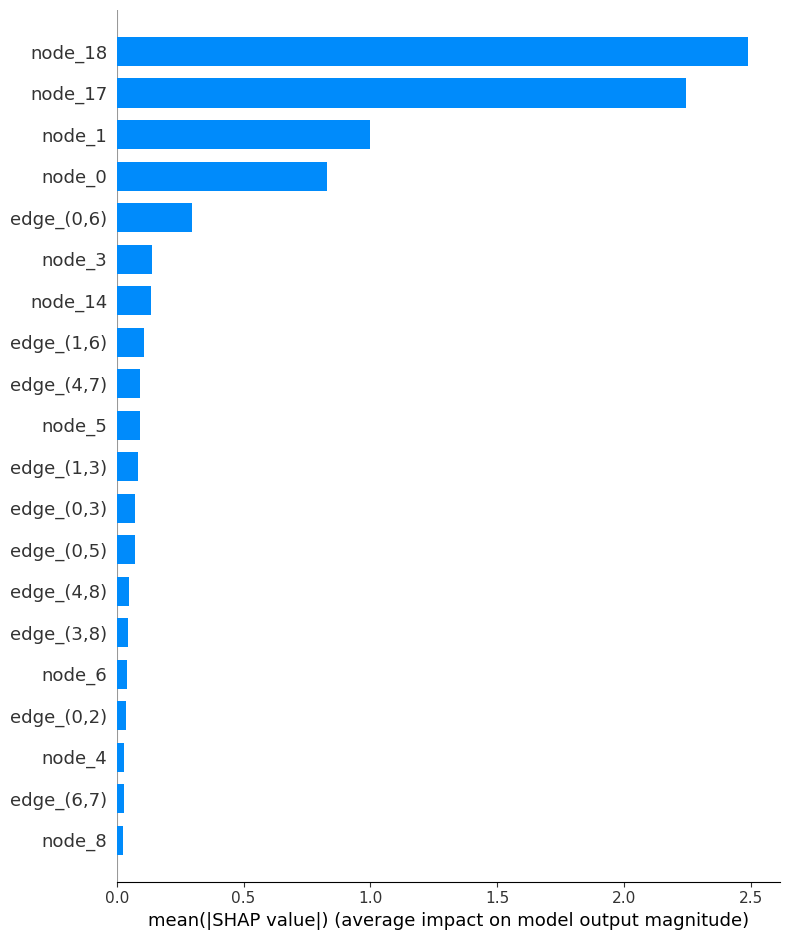

In [ ]:
import shap

# Assuming `model` is trained and `X` is your dataset
explainer = shap.Explainer(model, X)
shap_values = explainer(X)

# Create standard beeswarm summary plot
shap.summary_plot(shap_values, X)
shap.summary_plot(shap_values, X, plot_type="bar")